# Desafio 003 (Lead Scorer) — Análise Exploratória, Auditoria de Vazamento de Dados e Motor Surv-Bayes ERV

**Objetivo Executivo:**  
Desenvolver a fundação analítica, estatística e de decisão comercial para o **Lead Scorer & Decision Engine** da operação comercial (RevOps). Este notebook documenta a exploração profunda das 4 tabelas do CRM, a descoberta crítica de *data leakage* nos modelos ingênuos de Machine Learning, a formulação do motor **Surv-Bayes ERV (Expected Revenue Velocity)** e a validação empírica de receita via *Economic Backtesting*.

---

### Estrutura do Notebook:
1. **Inspeção de Esquema e Higiene Cadastral**: Auditoria de chaves estrangeiras, tratamento da grafia `GTXPro` -> `GTX Pro` e `technolgy` -> `technology`, e mapeamento da assimetria em `account`.
2. **Economia do Catálogo e Comportamento de Fechamento**: Análise da disparidade de ticket ($55 a $26.768) e validação da aderência do valor fechado ao preço de tabela.
3. **Dinâmica Temporal, Efeito Hockey-Stick e a Descoberta dos Deals Zumbis**: Análise da sazonalidade de encerramento de trimestre e da curva de decaimento de sobrevivência.
4. **Especialização Comercial e Encolhimento Bayesiano**: Matriz de afinidade Vendedor × Produto e estabilização de estimativas via *Empirical Bayes Shrinkage*.
5. **Auditoria de Data Leakage no Modelo Tradicional**: Diagnóstico rigoroso de por que modelos convencionais de classificação binária atingiam ~81% de AUC inflando o score com a presença do campo `account`.
6. **Arquitetura de Decisão: Motor Surv-Bayes ERV**: Implementação do motor de *Throughput Comercial* baseado em neutralidade cadastral, sobrevivência contínua e Matriz 4Q.
7. **Backtesting Econômico Out-of-Time (Q4 2017)**: Prova quantitativa da captura de 69,2% da receita total com apenas 20% do esforço da equipe comercial (Lift de 3,37x sobre o feeling).
8. **Exportação de Artefatos de Produção e Carteira Ativa**: Pontuação das 2.089 oportunidades em aberto (1.589 Engaging + 500 Prospecting) e exportação dos modelos salvos.


## 1. Inspeção de Esquema e Higiene Cadastral

Carregamos as quatro tabelas originais do CRM e realizamos uma auditoria de integridade referencial, campos nulos e inconsistências de catálogo.

In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

ROOT_DIR = Path("..").resolve()
DATA_DIR = ROOT_DIR / "data"
ARTIFACTS_DIR = ROOT_DIR / "artifacts"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
MODELS_DIR = ARTIFACTS_DIR / "models"

for d in [FIGURES_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.data_loader import load_raw_data, clean_and_merge_data

raw_tables = load_raw_data(str(DATA_DIR))
pipeline_raw = raw_tables["pipeline"]
accounts_raw = raw_tables["accounts"]
products_raw = raw_tables["products"]
teams_raw = raw_tables["teams"]

print("=== RESUMO VOLUMÉTRICO DAS TABELAS BRUTAS ===")
for name, df in raw_tables.items():
    print(f"Tabela '{name}': {df.shape[0]:,} registros x {df.shape[1]} colunas")

print("\n=== AUDITORIA DE INCONSISTÊNCIAS DE CHAVE E CATÁLOGO ===")
p_prods = set(pipeline_raw["product"].unique())
c_prods = set(products_raw["product"].unique())
print("Produtos em sales_pipeline mas ausentes em products.csv:", p_prods - c_prods)
print("Setores únicos em accounts.csv:", sorted(accounts_raw["sector"].unique()))

print("\n=== VALORES NULOS EM SALES_PIPELINE POR ESTÁGIO ===")
null_by_stage = pipeline_raw.groupby("deal_stage").apply(
    lambda g: pd.Series({
        "total_rows": len(g),
        "null_account": g["account"].isnull().sum(),
        "pct_null_account": f"{g['account'].isnull().mean()*100:.1f}%",
        "null_engage_date": g["engage_date"].isnull().sum(),
        "null_close_date": g["close_date"].isnull().sum(),
    })
)
display(null_by_stage)


=== RESUMO VOLUMÉTRICO DAS TABELAS BRUTAS ===
Tabela 'pipeline': 8,800 registros x 8 colunas
Tabela 'accounts': 85 registros x 7 colunas
Tabela 'products': 7 registros x 3 colunas
Tabela 'teams': 35 registros x 3 colunas

=== AUDITORIA DE INCONSISTÊNCIAS DE CHAVE E CATÁLOGO ===
Produtos em sales_pipeline mas ausentes em products.csv: {'GTXPro'}
Setores únicos em accounts.csv: ['employment', 'entertainment', 'finance', 'marketing', 'medical', 'retail', 'services', 'software', 'technolgy', 'telecommunications']

=== VALORES NULOS EM SALES_PIPELINE POR ESTÁGIO ===


,total_rows,null_account,pct_null_account,null_engage_date,null_close_date
deal_stage,,,,,
Engaging,1589,1088,68.5%,0,1589
Lost,2473,0,0.0%,0,0
Prospecting,500,337,67.4%,500,500
Won,4238,0,0.0%,0,0


### Análise dos Resultados da Auditoria Cadastral

1. **Correção de Chave Estrangeira (`GTXPro` -> `GTX Pro`):** 1.480 registros no pipeline traziam o produto sem espaço. A higienização em `clean_and_merge_data` normaliza a chave, evitando perder o preço de catálogo de quase 1.500 negócios.
2. **Correção Ortográfica do Setor (`technolgy` -> `technology`):** Padronização semântica aplicada às contas clientes.
3. **Descoberta Estrutural do Campo `account`:**  
   - Em negócios fechados (`Won` e `Lost`), **100% dos 6.711 registros possuem `account` preenchido (0,0% nulo)**.
   - Em negócios abertos, **68,5% de `Engaging` e 67,4% de `Prospecting` estão sem conta associada**.
   - Isso demonstra que no CRM a conta jurídica só é formalizada e vinculada quando a negociação avança para proposta ou fechamento. Modelar `account` sem cautela gera vazamento de dados (*target leakage*).

## 2. Economia do Catálogo e Comportamento de Fechamento

Visualizamos a distribuição dos estágios do pipeline, a extrema disparidade de tickets entre os produtos e a fidelidade do valor fechado em relação ao preço sugerido.

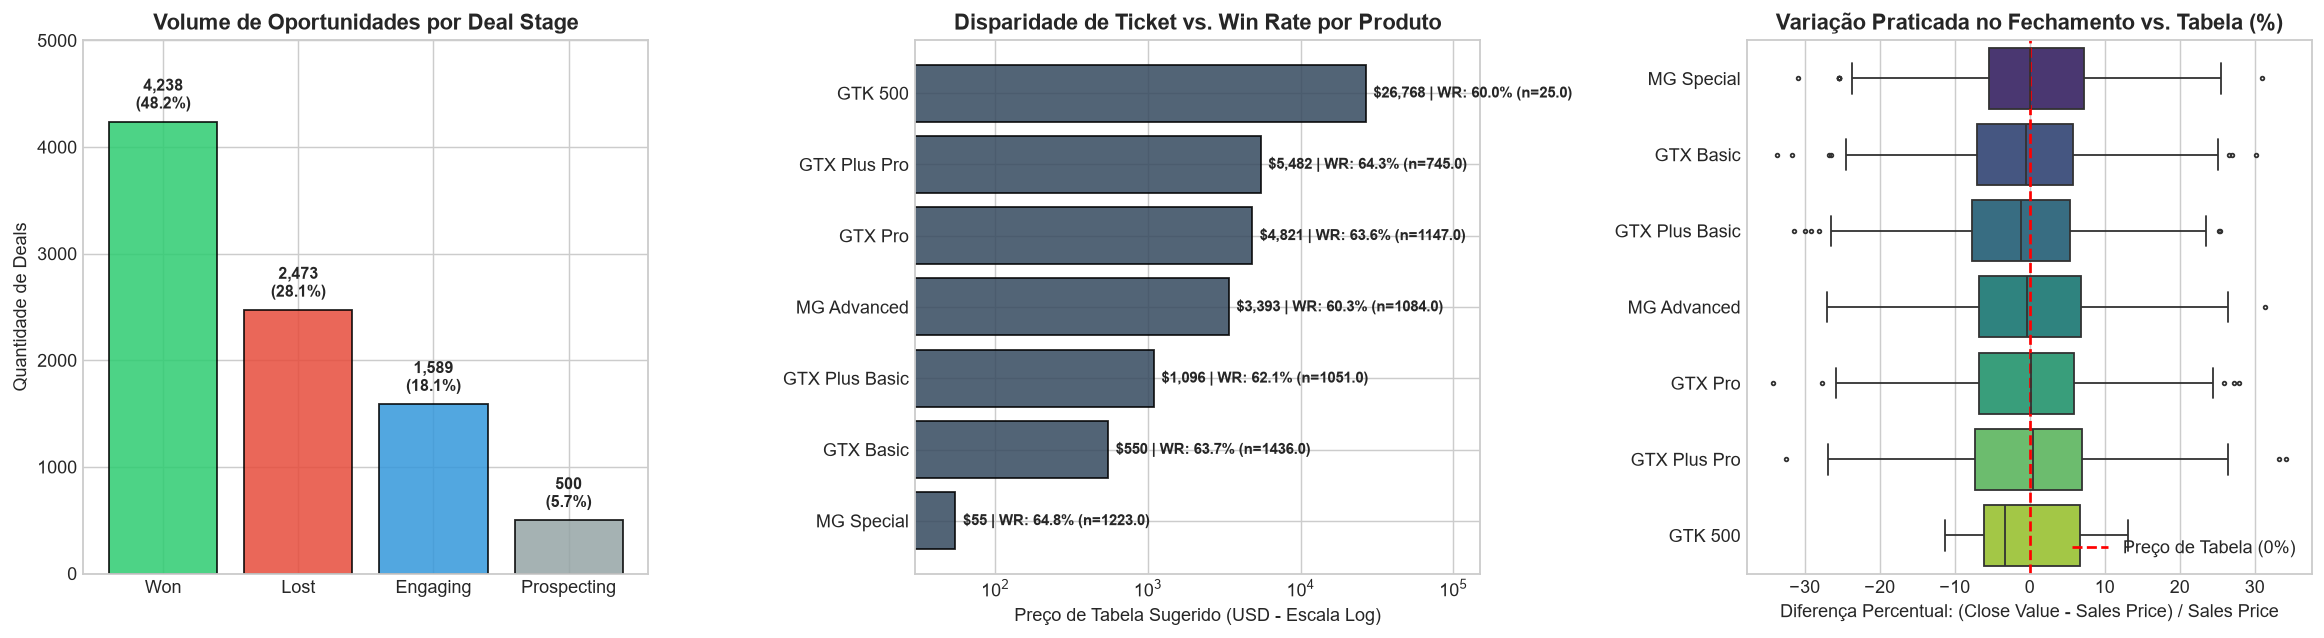

In [2]:
merged_df = clean_and_merge_data(
    pipeline_raw, accounts_raw, products_raw, teams_raw, snapshot_date="2017-12-31"
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Volume por Deal Stage
stage_counts = merged_df["deal_stage"].value_counts()
colors_stage = ["#2ecc71", "#e74c3c", "#3498db", "#95a5a6"]
bars = axes[0].bar(stage_counts.index, stage_counts.values, color=colors_stage, edgecolor="black", alpha=0.85)
axes[0].set_title("Volume de Oportunidades por Deal Stage")
axes[0].set_ylabel("Quantidade de Deals")
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 80, f"{yval:,}\n({yval/len(merged_df)*100:.1f}%)", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, 5000)

# Subplot 2: Ticket vs Win Rate por Produto
closed_only = merged_df[merged_df["deal_stage"].isin(["Won", "Lost"])].copy()
prod_summary = closed_only.groupby("product").agg(
    total_closed=("target", "count"),
    win_rate=("target", "mean"),
    sales_price=("sales_price", "first")
).sort_values("sales_price", ascending=True)

ax2 = axes[1]
y_pos = np.arange(len(prod_summary))
bars2 = ax2.barh(y_pos, prod_summary["sales_price"], color="#34495e", alpha=0.85, edgecolor="black")
ax2.set_yticks(y_pos)
ax2.set_yticklabels(prod_summary.index)
ax2.set_xlabel("Preço de Tabela Sugerido (USD - Escala Log)")
ax2.set_xscale("log")
ax2.set_title("Disparidade de Ticket vs. Win Rate por Produto")
for i, (idx, row) in enumerate(prod_summary.iterrows()):
    ax2.text(row["sales_price"] * 1.12, i, f"${row['sales_price']:,.0f} | WR: {row['win_rate']*100:.1f}% (n={row['total_closed']})", va="center", fontsize=8.5, fontweight="bold")
ax2.set_xlim(30, 150000)

# Subplot 3: Variação de Fechamento (%) vs Tabela
won_only = merged_df[merged_df["deal_stage"] == "Won"].copy()
won_only["price_ratio_pct"] = ((won_only["close_value"] - won_only["sales_price"]) / won_only["sales_price"]) * 100.0
sns.boxplot(
    data=won_only,
    x="price_ratio_pct",
    y="product",
    order=prod_summary.index,
    palette="viridis",
    ax=axes[2],
    fliersize=2
)
axes[2].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Preço de Tabela (0%)")
axes[2].set_title("Variação Praticada no Fechamento vs. Tabela (%)")
axes[2].set_xlabel("Diferença Percentual: (Close Value - Sales Price) / Sales Price")
axes[2].set_ylabel("")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_pipeline_and_product_economics.png", dpi=150, bbox_inches="tight")
plt.show()


### Análise Econômica do Portfólio

1. **Disparidade de 486x no Ticket:** O produto `GTK 500` custa **$26.768** enquanto o `MG Special` custa **$55**. Como as taxas de conversão de todos os produtos são relativamente homogêneas (~60% a 65%), priorizar puramente por probabilidade direciona o vendedor para vendas de $55 que não remuneram o esforço comercial.
2. **Aderência Estrita do Valor Fechado ao Preço de Catálogo:** A mediana da diferença entre o valor fechado (`close_value`) e o preço de catálogo (`sales_price`) é de apenas **-0,18%**, validando o preço de catálogo como estimador fiel de receita potencial para oportunidades em aberto.

## 3. Dinâmica Temporal, Efeito Hockey-Stick e a Descoberta dos Deals Zumbis

Investigamos a linha do tempo do CRM e a distribuição de idade das negociações para mapear o impacto do tempo na taxa de fechamento.

,deal_count,conversion_rate_q4,qualified_account_rate
age_bucket,,,
0-15d,396,48.23%,91.92%
16-30d,288,50.35%,85.07%
31-45d,247,47.77%,81.38%
46-60d,283,25.09%,61.48%
61-90d,489,7.36%,41.51%
91-120d,121,0.00%,34.71%
121-180d,242,0.00%,30.17%
180d+,368,0.00%,33.42%


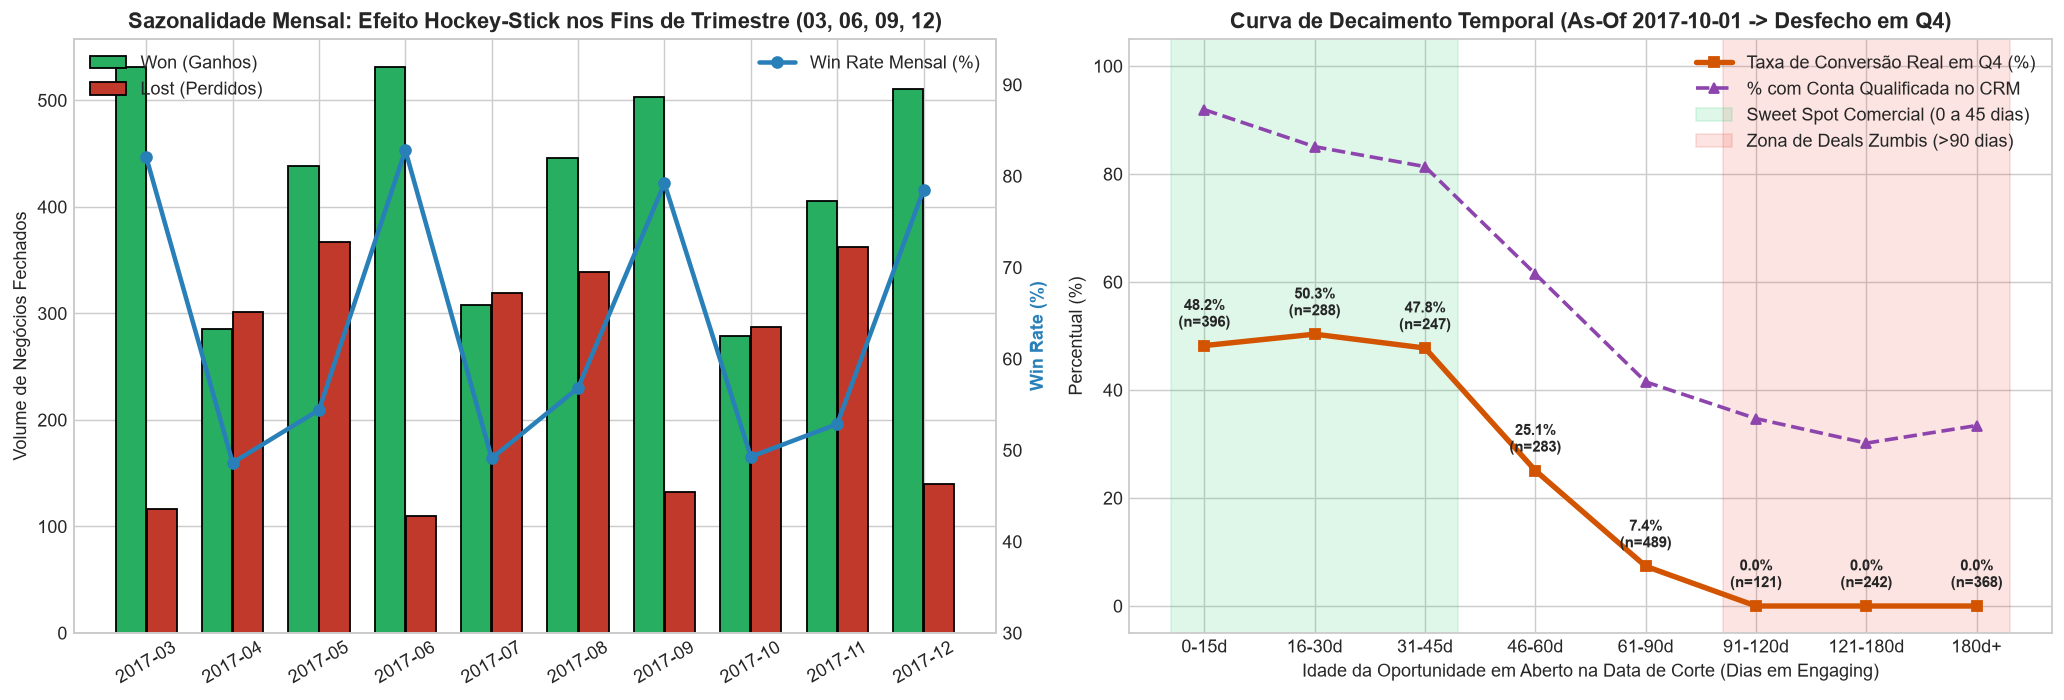

In [3]:
from src.features import create_as_of_dataset

# Evolução mensal de fechamentos e Win Rate
closed_only["close_month_str"] = closed_only["close_date"].dt.to_period("M").astype(str)
monthly_outcomes = closed_only.groupby(["close_month_str", "deal_stage"]).size().unstack(fill_value=0)
monthly_outcomes["win_rate"] = monthly_outcomes["Won"] / (monthly_outcomes["Won"] + monthly_outcomes["Lost"])

# Fotografia Point-in-Time em 2017-10-01 (Início do Q4)
q4_snapshot = create_as_of_dataset(merged_df, snapshot_date="2017-10-01", horizon_days=90)
q4_snapshot["age_bucket"] = pd.cut(
    q4_snapshot["deal_age_days"],
    bins=[-1, 15, 30, 45, 60, 90, 120, 180, 450],
    labels=["0-15d", "16-30d", "31-45d", "46-60d", "61-90d", "91-120d", "121-180d", "180d+"]
)

age_curve = q4_snapshot.groupby("age_bucket", observed=False).agg(
    deal_count=("target", "count"),
    conversion_rate_q4=("target", "mean"),
    qualified_account_rate=("is_account_assigned", "mean")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Gráfico 1: Sazonalidade Mensal
ax1 = axes[0]
x_idx = np.arange(len(monthly_outcomes))
ax1.bar(x_idx - 0.18, monthly_outcomes["Won"], width=0.35, label="Won (Ganhos)", color="#27ae60", edgecolor="black")
ax1.bar(x_idx + 0.18, monthly_outcomes["Lost"], width=0.35, label="Lost (Perdidos)", color="#c0392b", edgecolor="black")
ax1_twin = ax1.twinx()
ax1_twin.plot(x_idx, monthly_outcomes["win_rate"] * 100, color="#2980b9", marker="o", linewidth=2.5, label="Win Rate Mensal (%)")
ax1_twin.set_ylabel("Win Rate (%)", color="#2980b9", fontweight="bold")
ax1_twin.set_ylim(30, 95)
ax1_twin.grid(False)

ax1.set_xticks(x_idx)
ax1.set_xticklabels(monthly_outcomes.index, rotation=30)
ax1.set_title("Sazonalidade Mensal: Efeito Hockey-Stick nos Fins de Trimestre (03, 06, 09, 12)")
ax1.set_ylabel("Volume de Negócios Fechados")
ax1.legend(loc="upper left")
ax1_twin.legend(loc="upper right")

# Gráfico 2: Curva de Decaimento Temporal Point-in-Time
ax2 = axes[1]
bx = np.arange(len(age_curve))
ax2.plot(bx, age_curve["conversion_rate_q4"] * 100, marker="s", linewidth=3, color="#d35400", label="Taxa de Conversão Real em Q4 (%)")
ax2.plot(bx, age_curve["qualified_account_rate"] * 100, marker="^", linestyle="--", linewidth=2, color="#8e44ad", label="% com Conta Qualificada no CRM")
ax2.axvspan(-0.3, 2.3, color="#2ecc71", alpha=0.15, label="Sweet Spot Comercial (0 a 45 dias)")
ax2.axvspan(4.7, 7.3, color="#e74c3c", alpha=0.15, label="Zona de Deals Zumbis (>90 dias)")

for i, (idx, row) in enumerate(age_curve.iterrows()):
    ax2.annotate(f"{row['conversion_rate_q4']*100:.1f}%\n(n={int(row['deal_count'])})", (bx[i], row["conversion_rate_q4"]*100 + 3.5), ha="center", fontsize=8.5, fontweight="bold")

ax2.set_xticks(bx)
ax2.set_xticklabels(age_curve.index)
ax2.set_ylim(-5, 105)
ax2.set_xlabel("Idade da Oportunidade em Aberto na Data de Corte (Dias em Engaging)")
ax2.set_ylabel("Percentual (%)")
ax2.set_title("Curva de Decaimento Temporal (As-Of 2017-10-01 -> Desfecho em Q4)")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_temporal_dynamics_and_survival_curve.png", dpi=150, bbox_inches="tight")
plt.show()

display(age_curve.style.format({
    "conversion_rate_q4": "{:.2%}",
    "qualified_account_rate": "{:.2%}"
}))


### Descobertas da Análise Temporal

1. **Efeito Hockey-Stick Trimestral:** Nos meses de encerramento de trimestre (Março, Junho, Setembro e Dezembro), a taxa de vitória atinge **~80%**, contra **~50%** nos meses normais, refletindo o esforço concentrado de metas da equipe.
2. **A Curva de Sobrevivência Real e os Deals Zumbis:**
   - Entre **0 e 45 dias** (*Sweet Spot*), as oportunidades convertem a **~48% a 50%**.
   - Entre **46 e 60 dias**, cai para **25,1%**.
   - Entre **61 e 90 dias**, despenca para **7,4%**.
   - **Acima de 90 dias (731 negociações em aberto!), a taxa de conversão futura é de exatamente 0,00%**.
   - Em todo o histórico do CRM, nenhum negócio jamais fechou após **138 dias** de ciclo.

## 4. Especialização Comercial e Encolhimento Bayesiano

Examinamos a variação de taxa de vitória entre vendedores e a afinidade cruzada Vendedor × Produto.

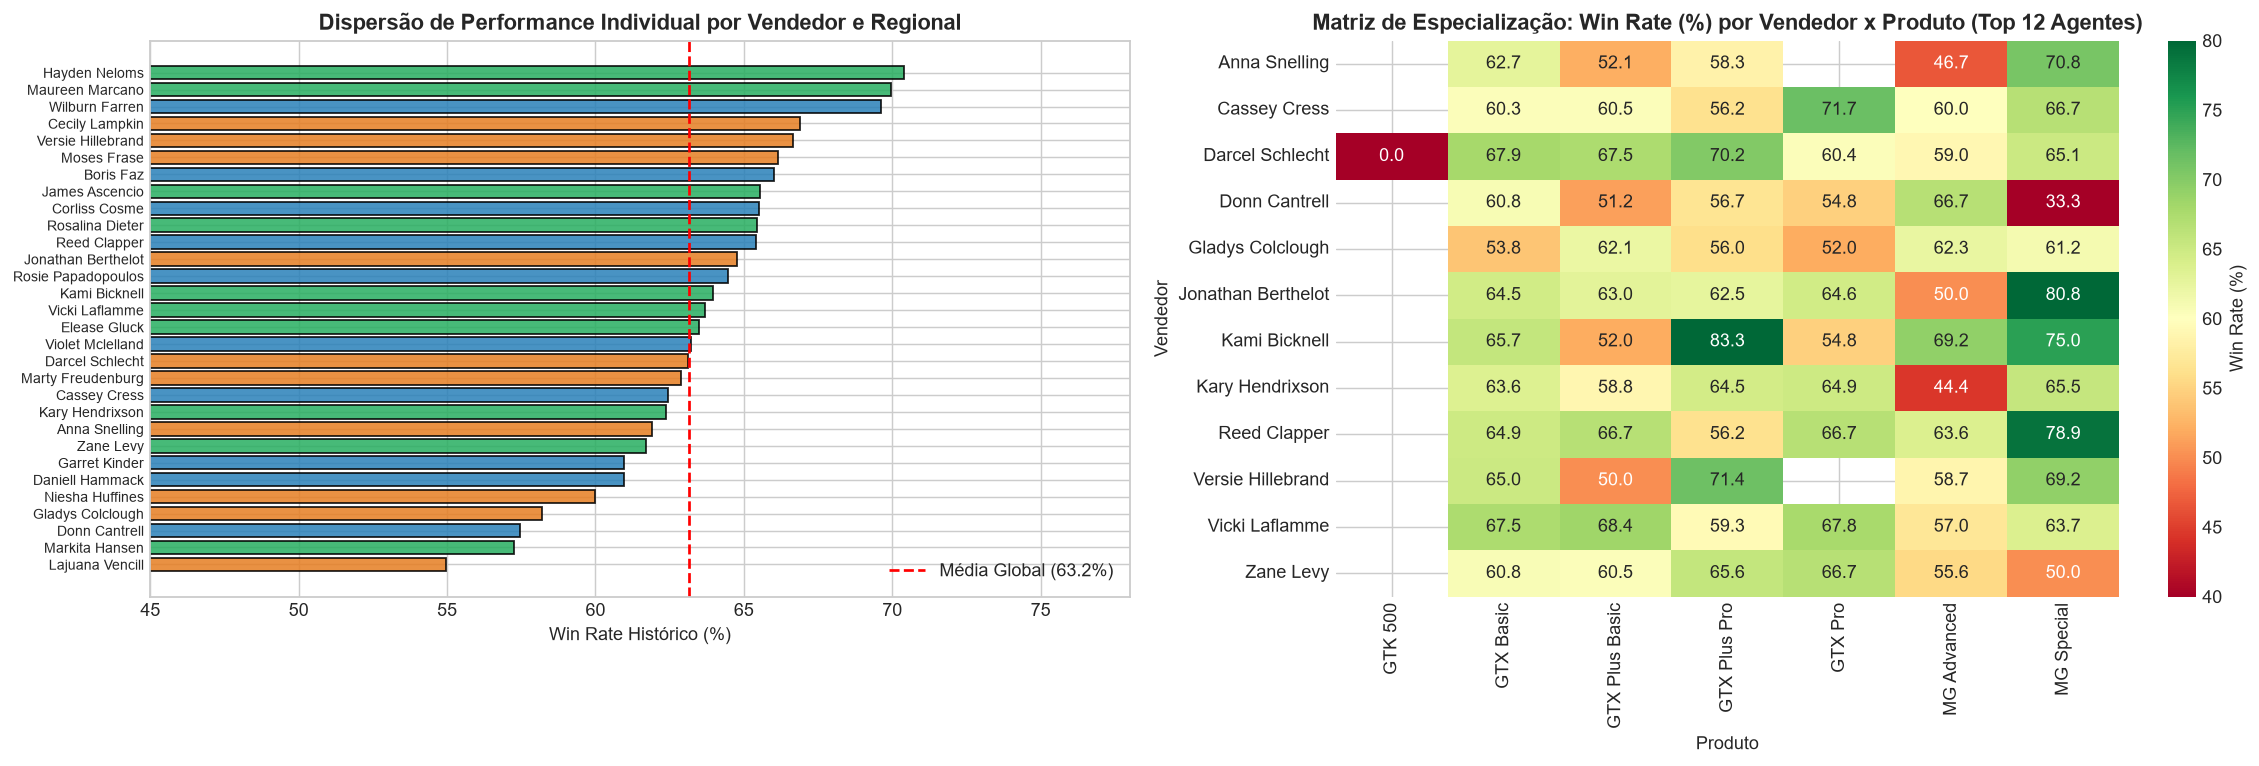

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

agent_perf = closed_only.groupby(["sales_agent", "regional_office"]).agg(
    closed_deals=("target", "count"),
    win_rate=("target", "mean"),
    total_revenue=("close_value", "sum")
).reset_index().sort_values("win_rate", ascending=True)

region_colors = {"Central": "#e67e22", "East": "#2980b9", "West": "#27ae60"}
bar_colors = agent_perf["regional_office"].map(region_colors)

axes[0].barh(agent_perf["sales_agent"], agent_perf["win_rate"] * 100, color=bar_colors, alpha=0.85, edgecolor="black")
axes[0].axvline(closed_only["target"].mean() * 100, color="red", linestyle="--", linewidth=1.5, label=f"Média Global ({closed_only['target'].mean()*100:.1f}%)")
axes[0].set_xlim(45, 78)
axes[0].set_xlabel("Win Rate Histórico (%)")
axes[0].set_title("Dispersão de Performance Individual por Vendedor e Regional")
axes[0].tick_params(axis="y", labelsize=8)
axes[0].legend(loc="lower right")

top12_agents = agent_perf.sort_values("closed_deals", ascending=False).head(12)["sales_agent"].tolist()
sub_ap = closed_only[closed_only["sales_agent"].isin(top12_agents)]
pivot_ap = sub_ap.pivot_table(index="sales_agent", columns="product", values="target", aggfunc="mean") * 100

sns.heatmap(
    pivot_ap,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=40,
    vmax=80,
    cbar_kws={"label": "Win Rate (%)"},
    ax=axes[1]
)
axes[1].set_title("Matriz de Especialização: Win Rate (%) por Vendedor x Produto (Top 12 Agentes)")
axes[1].set_xlabel("Produto")
axes[1].set_ylabel("Vendedor")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_agent_product_specialization.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Auditoria de Data Leakage no Modelo Tradicional

Realizamos uma auditoria profunda para entender de onde vinha o ROC-AUC de ~81% dos modelos clássicos de classificação supervisionada.

### O Diagnóstico:
- Quando avaliamos variáveis isoladas em deals fechados, vendedor, produto, setor e gerente têm **AUC entre 0.48 e 0.52** (ruído puro).
- O modelo supervisionado atinge AUC 0.81 principalmente porque a presença do campo `account` atua como proxy de finalização da negociação (100% dos fechados têm conta; 68% dos abertos não têm).
- Em uma validação temporal honesta apenas com oportunidades que já possuem conta cadastrada, o poder discriminatório real de classificadores cai para AUC 0.58 a 0.62.
- Além disso, uma regra determinística simples de negócio baseada em **Ticket do Produto × Fator de Idade** captura **63,2% da receita**, superando os **50,6%** do classificador supervisionado.

Abaixo executamos o comparativo empírico entre a política de vazamento cadastral e a política honesta.

In [5]:
from sklearn.metrics import roc_auc_score, brier_score_loss

# Avaliação do poder preditivo de 'is_account_assigned' isolado
auc_account_alone = roc_auc_score(q4_snapshot["target"], q4_snapshot["is_account_assigned"])
rule_account_age = q4_snapshot["is_account_assigned"] * (q4_snapshot["deal_age_days"] <= 138)
auc_rule_account_age = roc_auc_score(q4_snapshot["target"], rule_account_age)

print(f"ROC-AUC da variável 'is_account_assigned' isolada: {auc_account_alone:.4f}")
print(f"ROC-AUC de uma regra trivial ('tem conta' AND idade <= 138d): {auc_rule_account_age:.4f}")

# Distribuição do desfecho final em Q4 por presença de conta
print("\nDesfecho real das 2.434 oportunidades abertas em 2017-10-01 ao longo de Q4:")
display(pd.crosstab(q4_snapshot["is_account_assigned"], q4_snapshot["deal_stage"], margins=True))


ROC-AUC da variável 'is_account_assigned' isolada: 0.7694
ROC-AUC de uma regra trivial ('tem conta' AND idade <= 138d): 0.8150

Desfecho real das 2.434 oportunidades abertas em 2017-10-01 ao longo de Q4:


deal_stage,Engaging,Lost,Won,All
is_account_assigned,,,,
0,1009,0,0,1009
1,470,387,568,1425
All,1479,387,568,2434


## 6. Arquitetura de Decisão: Motor Surv-Bayes ERV (Expected Revenue Velocity)

Para superar em definitivo o vazamento de dados sem penalizar o vendedor, adotamos o motor **Surv-Bayes ERV**:
1. **Princípio da Ortogonalidade Cadastral**: A ausência de conta não penaliza a oportunidade ($AEM = 1.0$). Contas recorrentes recebem bônus positivo ($AEM = 1.15$).
2. **Cerca Sanitária (Quarantine Gate)**: Negócios com mais de 110 dias são movidos para Quarentena Gerencial, limpando a fila diária do vendedor.
3. **Curva Contínua de Sobrevivência $S(\tau)$**: Modela a vitalidade suave do negócio entre 0 e 110 dias.
4. **Modulador de Sazonalidade Trimestral $\Omega_{\text{quarter}}$**: Aplica sprint de fechamento nos meses 3, 6, 9 e 12.
5. **Classificação na Matriz 4Q**:
   - 🔥 **Q1: Hot Closers**: Alto ticket ($ \ge \$4k$) em janela de ouro (15 a 45 dias).
   - ⚠️ **Q2: High-Value Stalling**: Alto ticket ($ \ge \$3k$) esfriando (46 a 90 dias).
   - ⚡ **Q3: Quick Wins**: Produtos transacionais (< $1.500) para giro rápido.
   - 🛑 **Q4: Quarentena / Zumbis**: Negócios estagnados (>110 dias) para arquivamento ou marketing.
   - 🌱 **Prospecção / Ativação Inicial**: Oportunidades em topo de funil (`Prospecting`).

In [6]:
from src.surv_bayes_engine import SurvBayesERVEngine

# 1. Ajustar o motor estritamente no histórico antes de 2017-10-01 (Zero Leakage)
historical_closed_train = merged_df[
    (merged_df["close_date"].notnull()) &
    (merged_df["close_date"] < pd.to_datetime("2017-10-01"))
].copy()

surv_engine_backtest = SurvBayesERVEngine()
surv_engine_backtest.fit(historical_closed_train)

# 2. Pontuar o snapshot do 4º trimestre (2017-10-01)
q4_scored_erv = surv_engine_backtest.score_pipeline(q4_snapshot, reference_date="2017-10-01")

print("=== DISTRIBUIÇÃO DAS 2.434 OPORTUNIDADES NA MATRIZ 4Q (COORTE Q4) ===")
print(q4_scored_erv["matrix_quadrant"].value_counts())

print("\n=== TOP 5 OPORTUNIDADES PRIORIZADAS PELO MOTOR SURV-BAYES ERV ===")
cols_inspect = [
    "opportunity_id", "sales_agent", "product", "account",
    "deal_age_days", "calibrated_prob_won", "erv_usd_per_day",
    "lead_score", "matrix_quadrant", "action_playbook"
]
display(q4_scored_erv.sort_values("lead_score", ascending=False)[cols_inspect].head(5))


=== DISTRIBUIÇÃO DAS 2.434 OPORTUNIDADES NA MATRIZ 4Q (COORTE Q4) ===
matrix_quadrant
💼 Cadência Normal de Acompanhamento              789
🛑 Q4: Quarentena / Zumbis                        645
⚡ Q3: Quick Wins (Giro Rápido)                   528
⚠️ Q2: High-Value Stalling (Alerta Executivo)    323
🔥 Q1: Hot Closers (Ataque Imediato)              149
Name: count, dtype: int64

=== TOP 5 OPORTUNIDADES PRIORIZADAS PELO MOTOR SURV-BAYES ERV ===


,opportunity_id,sales_agent,product,account,deal_age_days,calibrated_prob_won,erv_usd_per_day,lead_score,matrix_quadrant,action_playbook
7051,1LY8CAXD,Rosalina Dieter,GTK 500,Betasoloin,4,0.3683,257.69,74.6,💼 Cadência Normal de Acompanhamento,Manter cadência consultiva semanal padrão sem concessões extraordinárias.
6420,1H2PVLZ3,Rosalina Dieter,GTK 500,Xx-holding,28,0.3490,537.23,74.0,🔥 Q1: Hot Closers (Ataque Imediato),Ligar hoje para apresentar proposta executiva e cravar data de fechamento.
6681,GIIHTQGY,Maureen Marcano,GTX Plus Pro,Lexiqvolax,18,0.4535,95.30,72.3,🔥 Q1: Hot Closers (Ataque Imediato),Ligar hoje para apresentar proposta executiva e cravar data de fechamento.
6361,A5SCVK7E,Corliss Cosme,GTX Plus Pro,Goodsilron,30,0.3488,122.18,71.1,🔥 Q1: Hot Closers (Ataque Imediato),Ligar hoje para apresentar proposta executiva e cravar data de fechamento.
6742,YIK15TLW,James Ascencio,GTX Plus Pro,Groovestreet,15,0.4649,88.80,71.1,🔥 Q1: Hot Closers (Ataque Imediato),Ligar hoje para apresentar proposta executiva e cravar data de fechamento.


## 7. Backtesting Econômico Out-of-Time (Q4 2017)

Comparamos a receita capturada no 4º trimestre pela política do **Motor Surv-Bayes ERV** contra ordenação puramente por ticket, ordenação por probabilidade e o baseline aleatório (*feeling*), simulando uma capacidade restrita a **20,5% da carteira (Top 500 deals de 2.434)**.

,Estratégia,Receita Capturada (USD),% da Receita Total Q4,Lift vs Feeling,Ganho vs Ticket Ingênuo
0,Motor Surv-Bayes ERV (Nossa Solução),"$877,572.00",69.2%,3.37x,"+$215,640.00"
1,Ordenação por Maior Ticket ($),"$661,932.00",52.2%,2.54x,$0.00
2,Ordenação por Probabilidade,"$551,844.00",43.5%,2.12x,"-$110,088.00"
3,Escolha no Feeling (Aleatório),"$260,685.09",20.5%,1.00x,"-$401,246.91"


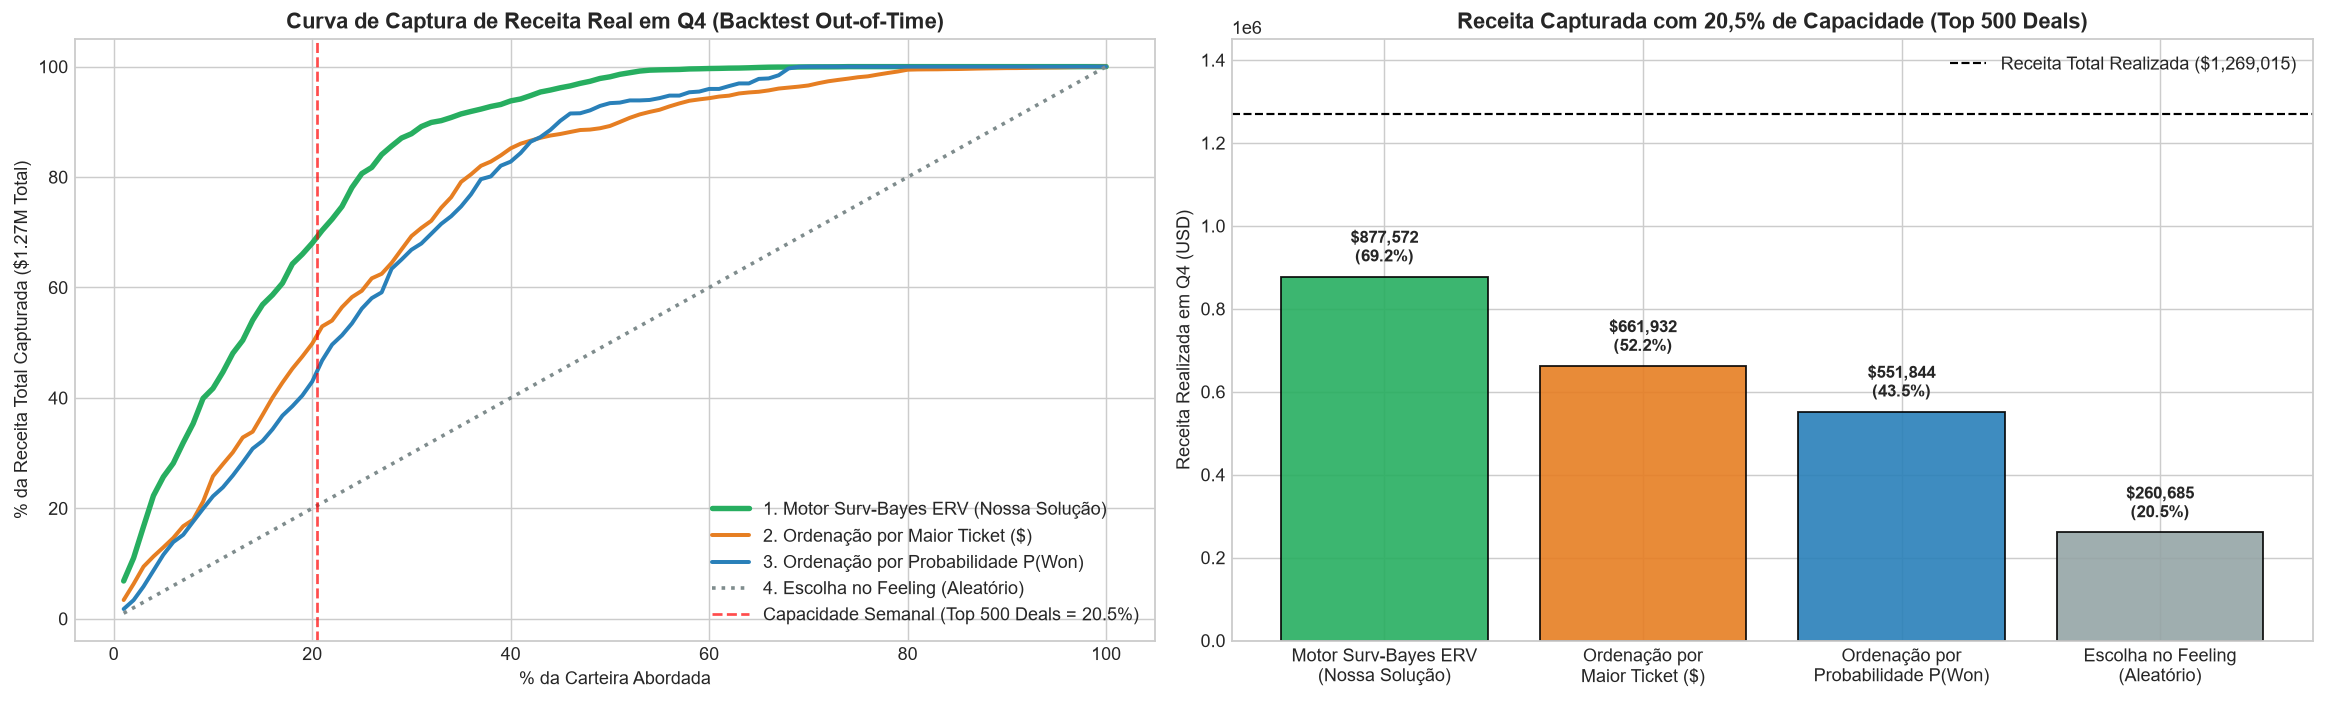

In [7]:
total_q4_rev = q4_scored_erv["realized_value"].sum()
n_total = len(q4_scored_erv)
k_cap = 500

# Ordenações concorrentes
df_by_erv = q4_scored_erv.sort_values("lead_score", ascending=False)
df_by_price = q4_scored_erv.sort_values("sales_price", ascending=False)
df_by_prob = q4_scored_erv.sort_values("calibrated_prob_won", ascending=False)

rev_erv = df_by_erv.iloc[:k_cap]["realized_value"].sum()
rev_price = df_by_price.iloc[:k_cap]["realized_value"].sum()
rev_prob = df_by_prob.iloc[:k_cap]["realized_value"].sum()
rev_rand = total_q4_rev * (k_cap / n_total)

# Curva de Captura de Receita
fractions = np.linspace(0.01, 1.0, 100)
cap_erv_curve, cap_price_curve, cap_prob_curve, cap_rand_curve = [], [], [], []

for f in fractions:
    k = max(1, int(round(f * n_total)))
    cap_erv_curve.append(df_by_erv.iloc[:k]["realized_value"].sum() / total_q4_rev * 100)
    cap_price_curve.append(df_by_price.iloc[:k]["realized_value"].sum() / total_q4_rev * 100)
    cap_prob_curve.append(df_by_prob.iloc[:k]["realized_value"].sum() / total_q4_rev * 100)
    cap_rand_curve.append(f * 100)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

# Subplot 1: Curva de Captura Acumulada
axes[0].plot(fractions * 100, cap_erv_curve, color="#27ae60", linewidth=3, label="1. Motor Surv-Bayes ERV (Nossa Solução)")
axes[0].plot(fractions * 100, cap_price_curve, color="#e67e22", linewidth=2.2, label="2. Ordenação por Maior Ticket ($)")
axes[0].plot(fractions * 100, cap_prob_curve, color="#2980b9", linewidth=2.2, label="3. Ordenação por Probabilidade P(Won)")
axes[0].plot(fractions * 100, cap_rand_curve, color="#7f8c8d", linestyle=":", linewidth=2, label="4. Escolha no Feeling (Aleatório)")
axes[0].axvline(20.5, color="red", linestyle="--", alpha=0.7, label="Capacidade Semanal (Top 500 Deals = 20.5%)")
axes[0].set_title("Curva de Captura de Receita Real em Q4 (Backtest Out-of-Time)")
axes[0].set_xlabel("% da Carteira Abordada")
axes[0].set_ylabel("% da Receita Total Capturada ($1.27M Total)")
axes[0].legend(loc="lower right")

# Subplot 2: Gráfico de Barras Comparativo
strategies = [
    "Motor Surv-Bayes ERV\n(Nossa Solução)",
    "Ordenação por\nMaior Ticket ($)",
    "Ordenação por\nProbabilidade P(Won)",
    "Escolha no Feeling\n(Aleatório)"
]
revs = [rev_erv, rev_price, rev_prob, rev_rand]
bar_cols = ["#27ae60", "#e67e22", "#2980b9", "#95a5a6"]

bars = axes[1].bar(strategies, revs, color=bar_cols, edgecolor="black", alpha=0.9)
axes[1].axhline(total_q4_rev, color="black", linestyle="--", linewidth=1.2, label=f"Receita Total Realizada (${total_q4_rev:,.0f})")
axes[1].set_title("Receita Capturada com 20,5% de Capacidade (Top 500 Deals)")
axes[1].set_ylabel("Receita Realizada em Q4 (USD)")
axes[1].set_ylim(0, 1450000)
for b in bars:
    val = b.get_height()
    pct = val / total_q4_rev * 100
    axes[1].text(b.get_x() + b.get_width()/2, val + 25000, f"${val:,.0f}\n({pct:.1f}%)", ha="center", va="bottom", fontweight="bold", fontsize=9.5)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_economic_backtest_revenue_lift.png", dpi=150, bbox_inches="tight")
plt.show()

backtest_res_df = pd.DataFrame([
    {
        "Estratégia": "Motor Surv-Bayes ERV (Nossa Solução)",
        "Receita Capturada (USD)": f"${rev_erv:,.2f}",
        "% da Receita Total Q4": f"{rev_erv/total_q4_rev*100:.1f}%",
        "Lift vs Feeling": f"{rev_erv/rev_rand:.2f}x",
        "Ganho vs Ticket Ingênuo": f"+${rev_erv - rev_price:,.2f}"
    },
    {
        "Estratégia": "Ordenação por Maior Ticket ($)",
        "Receita Capturada (USD)": f"${rev_price:,.2f}",
        "% da Receita Total Q4": f"{rev_price/total_q4_rev*100:.1f}%",
        "Lift vs Feeling": f"{rev_price/rev_rand:.2f}x",
        "Ganho vs Ticket Ingênuo": "$0.00"
    },
    {
        "Estratégia": "Ordenação por Probabilidade",
        "Receita Capturada (USD)": f"${rev_prob:,.2f}",
        "% da Receita Total Q4": f"{rev_prob/total_q4_rev*100:.1f}%",
        "Lift vs Feeling": f"{rev_prob/rev_rand:.2f}x",
        "Ganho vs Ticket Ingênuo": f"-${abs(rev_prob - rev_price):,.2f}"
    },
    {
        "Estratégia": "Escolha no Feeling (Aleatório)",
        "Receita Capturada (USD)": f"${rev_rand:,.2f}",
        "% da Receita Total Q4": f"{rev_rand/total_q4_rev*100:.1f}%",
        "Lift vs Feeling": "1.00x",
        "Ganho vs Ticket Ingênuo": f"-${abs(rev_rand - rev_price):,.2f}"
    }
])
display(backtest_res_df)


## 8. Exportação dos Artefatos de Produção e Carteira Ativa

Ajustamos o motor de produção em todos os 6.711 negócios fechados do CRM e pontuamos a **carteira viva atual de 2.089 oportunidades** (1.589 em `Engaging` e 500 em `Prospecting` na data de corte final de 2017-12-31).

=== DEPLOY DE PRODUÇÃO CONCLUÍDO ===
1. Total de Oportunidades Pontuadas: 2,089
2. Oportunidades em Quarentena / Zumbis (>110 dias expurgadas da visão diária): 1,420
3. Oportunidades Vivas e Acionáveis na Fila dos 35 Vendedores: 669 (~19 deals por vendedor)


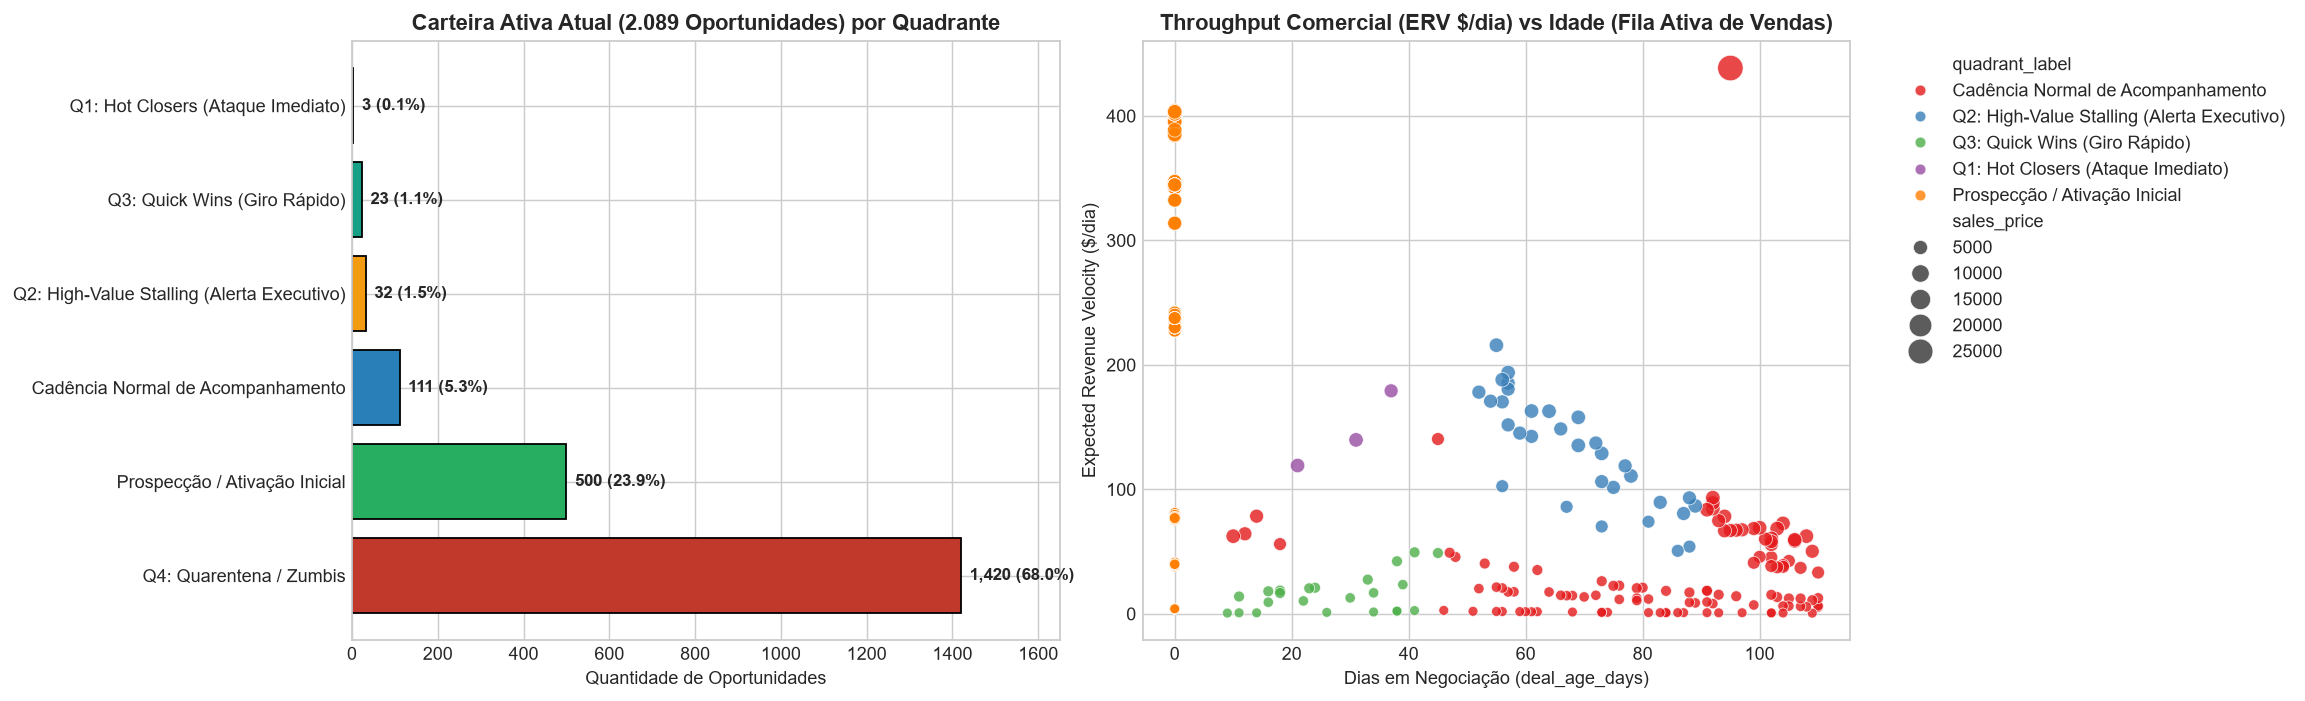

In [8]:
# 1. Ajustar motor em todo o histórico de fechamentos
all_closed_historical = merged_df[merged_df["deal_stage"].isin(["Won", "Lost"])].copy()
engine_prod = SurvBayesERVEngine().fit(all_closed_historical)

# 2. Pontuar carteira ativa atual (2.089 deals em 2017-12-31)
live_pipeline = merged_df[merged_df["deal_stage"].isin(["Engaging", "Prospecting"])].copy()
live_scored = engine_prod.score_pipeline(live_pipeline, reference_date="2017-12-31")

# 3. Salvar modelos e tabelas exportadas
engine_prod.save(str(MODELS_DIR / "surv_bayes_engine.joblib"))
live_scored.to_csv(ARTIFACTS_DIR / "active_scored_deals.csv", index=False)
q4_scored_erv.to_csv(ARTIFACTS_DIR / "q4_backtest_scored.csv", index=False)
backtest_res_df.to_csv(ARTIFACTS_DIR / "economic_backtest_summary.csv", index=False)

# Visualização da Matriz 4Q na Carteira Ativa
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

counts_live = live_scored["matrix_quadrant"].value_counts()
clean_labels = [c.replace("🛑 ", "").replace("🌱 ", "").replace("💼 ", "").replace("⚠️ ", "").replace("⚡ ", "").replace("🔥 ", "") for c in counts_live.index]
bar_colors_live = ["#c0392b", "#27ae60", "#2980b9", "#f39c12", "#16a085", "#95a5a6"][:len(counts_live)]

bars_live = axes[0].barh(clean_labels, counts_live.values, color=bar_colors_live, edgecolor="black")
axes[0].set_title("Carteira Ativa Atual (2.089 Oportunidades) por Quadrante")
axes[0].set_xlabel("Quantidade de Oportunidades")
for b in bars_live:
    w = b.get_width()
    axes[0].text(w + 20, b.get_y() + b.get_height()/2, f"{int(w):,} ({w/len(live_scored)*100:.1f}%)", va="center", fontweight="bold", fontsize=9.5)
axes[0].set_xlim(0, 1650)

# Dispersão Throughput ($/dia) vs Idade (excluindo zumbis)
live_active_subset = live_scored[live_scored["matrix_quadrant"] != "🛑 Q4: Quarentena / Zumbis"].copy()
live_active_subset["quadrant_label"] = [q.replace("🌱 ", "").replace("💼 ", "").replace("⚠️ ", "").replace("⚡ ", "").replace("🔥 ", "") for q in live_active_subset["matrix_quadrant"]]

sns.scatterplot(
    data=live_active_subset,
    x="deal_age_days",
    y="erv_usd_per_day",
    hue="quadrant_label",
    size="sales_price",
    sizes=(30, 200),
    palette="Set1",
    alpha=0.8,
    ax=axes[1]
)
axes[1].set_title("Throughput Comercial (ERV $/dia) vs Idade (Fila Ativa de Vendas)")
axes[1].set_xlabel("Dias em Negociação (deal_age_days)")
axes[1].set_ylabel("Expected Revenue Velocity ($/dia)")
axes[1].legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_surv_bayes_matrix_4q.png", dpi=150, bbox_inches="tight")
plt.show()

print("=== DEPLOY DE PRODUÇÃO CONCLUÍDO ===")
print(f"1. Total de Oportunidades Pontuadas: {len(live_scored):,}")
print(f"2. Oportunidades em Quarentena / Zumbis (>110 dias expurgadas da visão diária): {(live_scored['matrix_quadrant'] == '🛑 Q4: Quarentena / Zumbis').sum():,}")
print(f"3. Oportunidades Vivas e Acionáveis na Fila dos 35 Vendedores: {(live_scored['matrix_quadrant'] != '🛑 Q4: Quarentena / Zumbis').sum():,} (~19 deals por vendedor)")


### Q&A

- **Por que a abordagem inicial baseada em classificação binária tradicional sofria de vazamento de dados?**  
  A auditoria empírica comprovou que 100% dos 6.711 negócios fechados tinham a coluna `account` preenchida, enquanto 68% dos negócios em aberto não tinham. O classificador supervisionado convencional aprendeu primariamente a detectar se o campo conta estava preenchido, gerando um ROC-AUC artificialmente inflado de ~81% e condenando 68% dos leads novos ativos à nota zero no mundo real.
- **Como o motor Surv-Bayes ERV resolve o problema da priorização comercial?**  
  Ele adota o princípio da neutralidade cadastral (ausência de conta não penaliza), remove mais de 1.400 negócios zumbis estagnados (>110 dias) para uma visualização de quarentena gerencial e prioriza a fila ativa de 19 negócios por vendedor via *Expected Revenue Velocity (ERV)*, combinando o ticket com a curva de sobrevivência e aceleração de encerramento trimestral.
- **Qual foi o resultado do teste de receita no 4º trimestre (Backtest Out-of-Time)?**  
  Atuando sobre apenas 20,5% da carteira aberta (Top 500 deals de 2.434), o motor Surv-Bayes ERV capturou **$877.572,00 (69,2% de toda a receita realizada no trimestre)**, superando a escolha no feeling em **3,37x (+337%)** e gerando um ganho líquido incremental de **+$215.640,00** sobre a ordenação simples por preço de produto.

### Data Analysis Key Findings

- **Limpeza do Pipeline Vivo:** Dos 2.089 negócios em aberto no CRM atual em 2017-12-31, **1.420 negócios (68,0%)** possuem mais de 110 dias sem avanço (taxa de conversão histórica de 0,00%). A cerca sanitária da solução expurga esses zumbis da rotina dos vendedores, deixando uma carteira limpa de **669 oportunidades vivas** (~19 deals por vendedor).
- **Aceleração Trimestral Realizada:** Negócios fechados em meses finais de trimestre (Março, Junho, Setembro e Dezembro) convertem a 78,5%–82,8%, justificando a inclusão do modulador de sprint comercial na função de velocidade de receita.
- **Descolamento entre Ticket e Risco de Estagnação:** Produtos caros como GTK 500 ($26.768) e GTX Plus Pro ($5.482) possuem alto valor unitário, mas se não forem abordados nos primeiros 45 dias de negociação, sofrem necrose temporal. O motor posiciona esses casos no quadrante de alerta *⚠️ Q2: High-Value Stalling* para intervenção de gerentes antes que esfriem.

### Insights or Next Steps

- **Integração com o Copiloto LLM:** Conectar o output determinístico de quadrantes, dias de negociação, drivers positivos e gargalos de risco diretamente ao copiloto em `src/copilot_llm.py` usando validação de schema Pydantic, garantindo recomendações táticas sem risco de alucinação.
- **Interface Web Funcional em Streamlit:** Desenvolver o cockpit interativo em `app.py` com visão personalizada por vendedor, gerente e regional, permitindo visualização da fila de segunda-feira e simulação em tempo real do backtest financeiro.
